In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

from telegram_scraper import study, viz
from telegram_scraper.study import CHANNELS, CHANNEL_ORDER, SHORT_NAMES, WINDOW
from telegram_scraper.analysis import stats

viz.apply_style()
np.random.seed(study.SEED)
pd.set_option("display.max_colwidth", 150)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
posts = study.load_posts()
events = study.verified_events(posts)
f"{len(posts):,} posts from {posts['channel_slug'].nunique()} channels, {posts['timestamp'].min():%Y-%m-%d} to {posts['timestamp'].max():%Y-%m-%d}"

'12,221 posts from 6 channels, 2026-02-28 to 2026-04-17'

# 06 · Media: do visuals carry a different message?

> **Question.** Does Press TV use visuals for different topics than text (the first-pass "visuals for diplomacy" / Nye claim), and does media type change reach?
>
> **Answer.** No: Press TV is only 1.6% text-only, so the old media-vs-text contrast was mostly video vs photo; with correct coding diplomacy topics are 4% of Press TV's video posts, 18% of its photo posts and 26% of its link-preview cards (bias-corrected V = 0.33 for the whole media-by-topic table), and a video gets 0.995x (CI 0.98-1.01) the views of a photo.

## 1. Editorial media mix with confidence intervals

Media class per post: **video** (video or animation anywhere in the post) > **photo** > **link preview** (a web-page card; not editorial media) > **text only**. Notebook 01 showed the mix as stacked bars; here each share carries a Wilson 95% interval so differences between channels can be judged against sampling noise.

media_class,video,photo,link preview,text only
channel_slug,,,,
Press TV,47.7,44.8,5.9,1.6
IRNA,11.5,51.9,22.6,14.0
IDF,0.0,0.3,13.1,86.6
ILTV,52.0,37.1,0.0,11.0
ToI,0.0,99.8,0.2,0.0
JBN,44.2,44.9,0.0,10.9


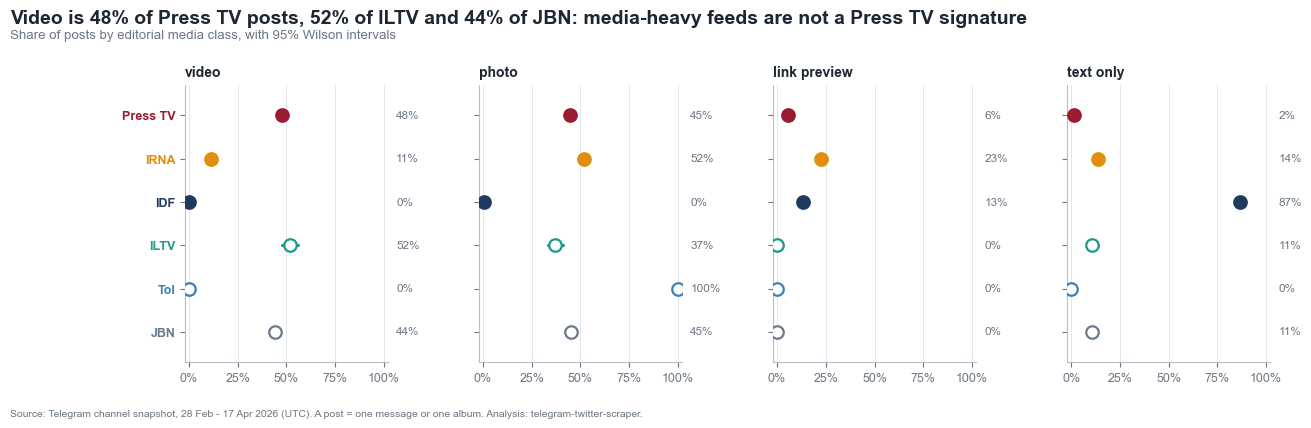

In [2]:
CLASSES = ["video", "photo", "link preview", "text only"]
rows = []
for cls in CLASSES:
    t = stats.share_table(posts.assign(_f=posts["media_class"] == cls), "channel_slug", "_f").assign(media_class=cls)
    rows.append(t)
mix = pd.concat(rows, ignore_index=True)
mix_w = mix.pivot(index="channel_slug", columns="media_class", values="share").reindex(CHANNEL_ORDER)[CLASSES]
display((mix_w * 100).round(1).rename(index=SHORT_NAMES))

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True, gridspec_kw={"wspace": 0.45})
for ax, cls in zip(axes, CLASSES):
    sub = mix[mix["media_class"] == cls].set_index("channel_slug").reindex(CHANNEL_ORDER).reset_index().assign(channel=lambda d: d["channel_slug"].map(SHORT_NAMES))
    viz.dot_whisker(ax, sub, label_col="channel", est_col="share", lo_col="ci_low", hi_col="ci_high", value_fmt="{:.0%}")
    ax.set_title(cls, fontsize=10); ax.xaxis.set_major_formatter(PercentFormatter(1.0)); ax.set_xlim(-0.02, 1.02)
vid = mix_w["video"]
viz.headline(fig, f"Video is {vid['presstv']:.0%} of Press TV posts, {vid['iltvnews']:.0%} of ILTV and {vid['jewishbreakingnewstelegram']:.0%} of JBN: media-heavy feeds are not a Press TV signature",
             "Share of posts by editorial media class, with 95% Wilson intervals", y=1.04, wrap=110)
viz.done(fig, "06_media_shares", mix)

**Reading the figure.** With intervals, the channels fall into three groups. Video-and-photo news feeds: Press TV (48% video, 45% photo), ILTV (52% / 37%) and JBN (44% / 45%) are statistically close on video. IRNA is photo-led (52%) with a quarter of posts as link cards (23%) and 14% plain text. The IDF is text (87%) and ToI is photo (99.8%). Press TV's text-only share (1.6%) is the lowest of any channel except ToI, so for Press TV there is almost no "text" to contrast with media.

## 2. Does Press TV use visuals for different topics than plain text? (recomputed correctly)

The first-pass finding that Press TV's media posts differ in topic from its text-only posts used a **photo-only** media flag, so every video post was counted as "text only". Here the same question is asked with the correct media class, using the single joint topic model from notebook 03 (posts the model left unassigned are excluded). Method: chi-square test of independence between media group and topic after merging sparse topics so every expected cell count is at least 5, with bias-corrected Cramér's V as the effect size (V ≈ 0.1 small, 0.3 medium). All p-values in this notebook are collected and Benjamini-Hochberg adjusted together at the end.

Press TV posts with an assigned topic: 4,289
{'video': 2159, 'photo': 1886, 'link preview': 223, 'text only': 21}


,n,n_groups,n_categories,chi2,dof,p_value,min_expected_count,cramers_v,cramers_v_bias_corrected
coding,,,,,,,,,
new coding: video / photo / none,4289,3,21,974.311184,40,0.0,5.233854,0.33702,0.330105
new coding: any editorial media vs none,4289,2,21,162.623991,20,0.0,5.233854,0.194722,0.182374
OLD coding: photo-only flag,4289,2,40,714.743437,39,0.0,5.868035,0.408223,0.396973


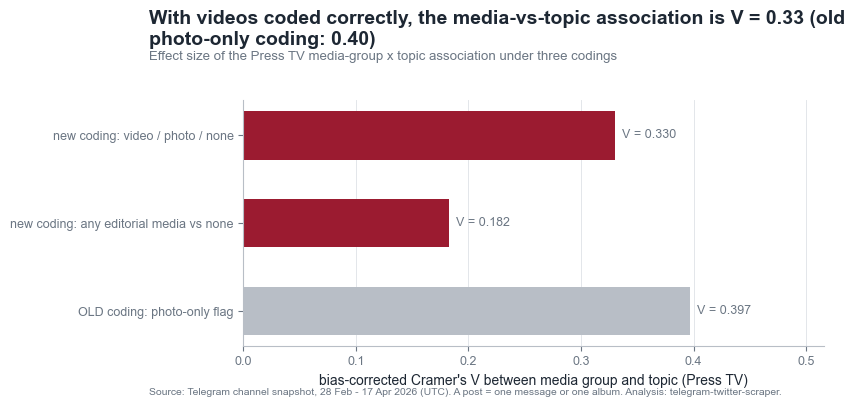

In [3]:
TESTS = []   # every hypothesis test in this notebook: name, family, raw p, effect size
def add_test(name, family, p, effect=None, effect_name=""):
    TESTS.append({"test": name, "family": family, "p_raw": float(p), "effect": effect, "effect_name": effect_name})

assign = pd.read_parquet(study.CACHE_DIR / "topic_assignments.parquet")
tp = posts.merge(assign[["post_id", "topic_id", "topic_label"]], on="post_id", how="inner")
tp = tp[tp["topic_id"] != -1].copy()
tp["media3"] = tp["media_class"].map({"video": "video", "photo": "photo", "link preview": "no editorial media", "text only": "no editorial media", "other media": "photo"})
tp["old_flag"] = np.where(tp["has_photo"], "photo (old flag: media)", "no photo (old flag: text-only)")
tp["media_binary"] = np.where(tp["has_editorial_media"], "editorial media", "no editorial media")
ptv = tp[tp["channel_slug"] == "presstv"]
print(f"Press TV posts with an assigned topic: {len(ptv):,}")
print(ptv["media_class"].value_counts().to_dict())

res = {}
for name, col in [("new coding: video / photo / none", "media3"), ("new coding: any editorial media vs none", "media_binary"), ("OLD coding: photo-only flag", "old_flag")]:
    r = stats.chi_square_by_group(ptv, col, "topic_label")
    res[name] = r
    add_test(f"Press TV media vs topic - {name}", "press_tv_topic_split", r["p_value"], r["cramers_v_bias_corrected"], "bias-corrected Cramer's V")
chi = pd.DataFrame(res).T[["n", "n_groups", "n_categories", "chi2", "dof", "p_value", "min_expected_count", "cramers_v", "cramers_v_bias_corrected"]]
chi.index.name = "coding"
display(chi.round(4))

fig, ax = plt.subplots(figsize=(7.5, 3.2))
vals = chi["cramers_v_bias_corrected"]
ax.barh(list(vals.index)[::-1], vals.to_numpy()[::-1], color=[viz.ACCENT if "OLD" not in k else "#B8BEC6" for k in vals.index][::-1], height=0.55)
for y, v in enumerate(vals.to_numpy()[::-1]): ax.text(v, y, f"  V = {v:.3f}", va="center", fontsize=9, color=viz.MUTED)
ax.set_xlim(0, max(0.3, vals.max() * 1.3)); ax.grid(axis="y", visible=False); ax.set_xlabel("bias-corrected Cramer's V between media group and topic (Press TV)")
old_v, new_v = vals.iloc[2], vals.iloc[0]
viz.headline(fig, f"With videos coded correctly, the media-vs-topic association is V = {new_v:.2f} (old photo-only coding: {old_v:.2f})", "Effect size of the Press TV media-group x topic association under three codings", y=1.04, wrap=80)
viz.done(fig, "06_coding_effect", chi.reset_index())

**Reading the table and figures.** Press TV media group is strongly associated with topic: chi-square 974 on 40 degrees of freedom, bias-corrected Cramér's V = 0.33, BH-adjusted p ≈ 0. But the association is not the one the first pass described.

- The old photo-only flag gave V = 0.40, and a binary "any editorial media vs none" coding gives V = 0.18. The strongest contrast is **between video and photo**, not between media and text.
- Only 21 of the 4,289 assigned Press TV posts are text-only; the 244 posts with no editorial media are 223 link-preview cards plus those 21. The old "text-only" group was mostly videos.
- What separates video from photo (second figure): video over-indexes on rallies (+8.7 pp vs photo), commentary shows (+8.1 pp; e.g. David Miller), "occupied territories" missile footage (+6.6 pp) and Khamenei/Leader items (+3.7 pp); photo posts over-index on Pezeshkian (-4.0 pp), Hormuz shipping (-3.7 pp), Ghalibaf (-2.9 pp), Araghchi (-2.7 pp), the IRGC and UN diplomacy, i.e. portraits of officials. So format follows content type, as at any picture desk.

### What drives the association?

The topic-by-topic gap between video posts and photo posts on Press TV (share of each media group's assigned posts), top seven topics on each side. Press TV's "text only" group is tiny (see the counts above), so the contrast that matters is video vs. photo vs. link-preview cards.

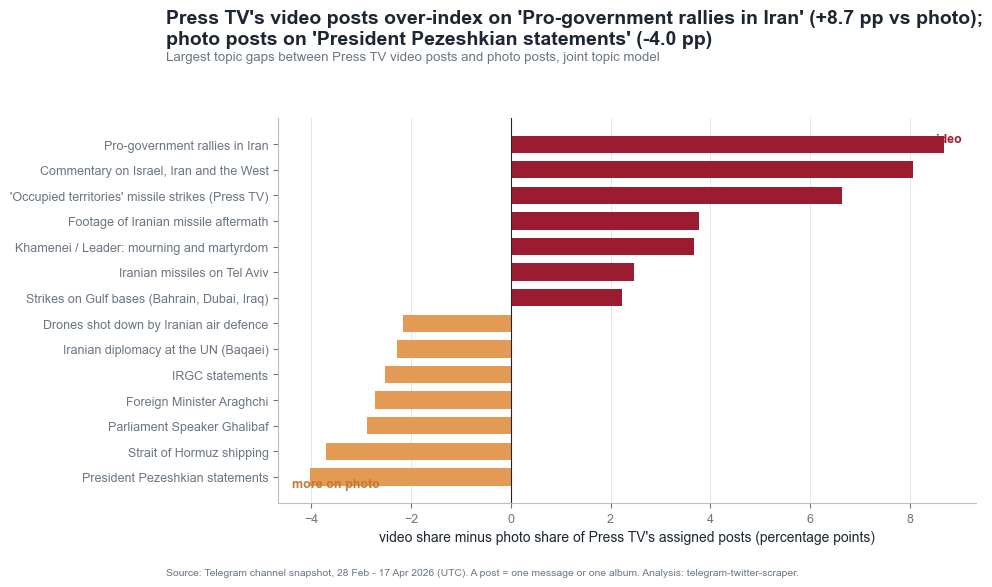

topics of Press TV's link-preview / text-only posts (no editorial media):


,posts
topic_label,
IRGC statements,19
Strait of Hormuz shipping,17
Khamenei / Leader: mourning and martyrdom,16
Operation True Promise 4 waves,15
Foreign Minister Araghchi,15


In [4]:
tab = pd.crosstab(ptv["topic_label"], ptv["media3"], normalize="columns")
gap = (tab["video"] - tab["photo"]).sort_values()
sel = pd.concat([gap.head(7), gap.tail(7)])
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh([lab[:52] for lab in sel.index], sel.to_numpy() * 100, color=[viz.ACCENT if v > 0 else "#E39A55" for v in sel], height=0.68)
ax.axvline(0, color=viz.INK, lw=0.8); ax.grid(axis="y", visible=False)
ax.set_xlabel("video share minus photo share of Press TV's assigned posts (percentage points)")
ax.text(0.98, 0.96, "more on video", transform=ax.transAxes, ha="right", va="top", color=viz.ACCENT, fontsize=9, fontweight="bold")
ax.text(0.02, 0.04, "more on photo", transform=ax.transAxes, ha="left", color="#C27A32", fontsize=9, fontweight="bold")
viz.headline(fig, f"Press TV's video posts over-index on '{gap.index[-1]}' ({gap.iloc[-1] * 100:+.1f} pp vs photo); photo posts on '{gap.index[0]}' ({gap.iloc[0] * 100:+.1f} pp)",
             "Largest topic gaps between Press TV video posts and photo posts, joint topic model", y=1.02, wrap=90)
viz.done(fig, "06_press_tv_topic_gaps", tab.assign(video_minus_photo=tab["video"] - tab["photo"]).reset_index())
nm = pd.crosstab(ptv["topic_label"], ptv["media_class"]).loc[:, ["link preview", "text only"]].sum(axis=1).sort_values(ascending=False).head(5)
print("topics of Press TV's link-preview / text-only posts (no editorial media):"); display(nm.rename("posts").to_frame())

## 3. The old "visuals for diplomacy" story, checked head-on

The first-pass reading (using Nye's soft-power frame) was that Press TV puts visuals on diplomacy and official actors and Hormuz, and keeps Khamenei/leader content as text. Three topic groups from notebook 03 are tracked: **diplomacy and official actors** (Islamabad talks, Araghchi, Pezeshkian, Ghalibaf, UN diplomacy, Lebanon ceasefire), **Hormuz and the war economy** (Hormuz shipping, oil prices) and **Khamenei / Leader and funerals**. For each, the share of Press TV's assigned posts by media class, plus a two-proportion test of "has editorial media" vs "text only or link preview".

,group,share_with_media,share_without_media,diff_pp,ci_low_pp,ci_high_pp,p_fisher,n_media,n_none
0,diplomacy / official actors,0.1058,0.2418,-13.5994,-19.4170,-8.5566,0.0000,4045,244
1,Hormuz / war economy,0.0452,0.0820,-3.6726,-7.8398,-0.7628,0.0128,4045,244
2,Khamenei / Leader and funerals,0.1328,0.0738,5.8986,1.7909,8.7698,0.0058,4045,244


first-pass claims: diplomacy +7.7 pp, Hormuz +5.5 pp for media posts; Khamenei/leader -11.3 pp (text-only over-index)


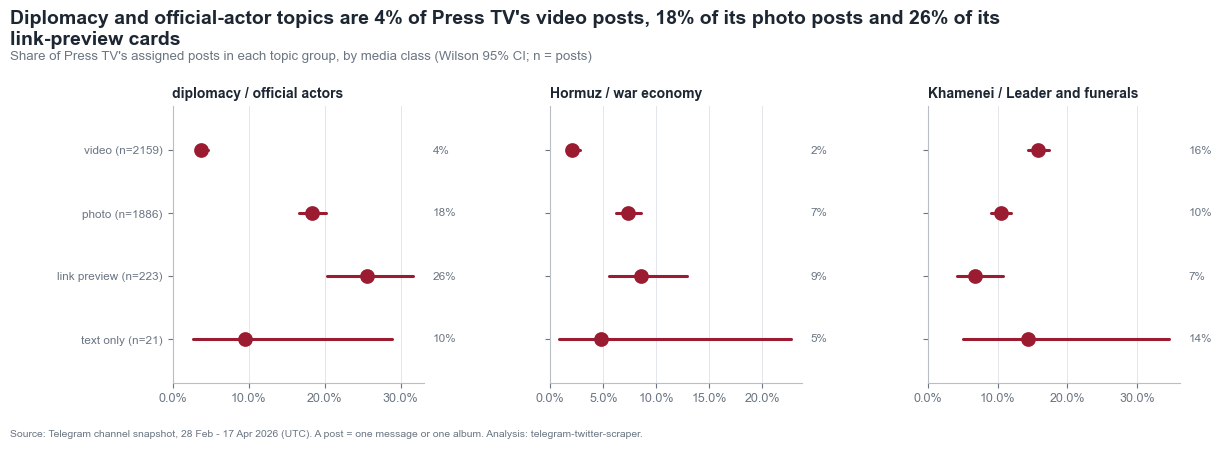

In [5]:
GROUPS = {
    "diplomacy / official actors": [17, 44, 6, 15, 46, 16],
    "Hormuz / war economy": [50, 43],
    "Khamenei / Leader and funerals": [18, 19],
}
rows, tests = [], []
for g, ids in GROUPS.items():
    flag = ptv["topic_id"].isin(ids)
    t = stats.share_table(ptv.assign(_f=flag), "media_class", "_f").assign(group=g)
    rows.append(t)
    media, none = ptv["has_editorial_media"], ~ptv["has_editorial_media"]
    r = stats.two_proportion_test(int(flag[media].sum()), int(media.sum()), int(flag[none].sum()), int(none.sum()))
    tests.append({"group": g, "share_with_media": r["p1"], "share_without_media": r["p2"], "diff_pp": 100 * r["diff"], "ci_low_pp": 100 * r["ci_low"], "ci_high_pp": 100 * r["ci_high"], "p_fisher": r["p_fisher"], "n_media": int(media.sum()), "n_none": int(none.sum())})
    add_test(f"Press TV: {g} share, media vs none", "press_tv_topic_split", r["p_fisher"], r["diff"], "difference in proportions")
shares_by_media = pd.concat(rows, ignore_index=True)
claims = pd.DataFrame(tests)
display(claims.round(4))
print("first-pass claims: diplomacy +7.7 pp, Hormuz +5.5 pp for media posts; Khamenei/leader -11.3 pp (text-only over-index)")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True, gridspec_kw={"wspace": 0.5})
cls_order = ["video", "photo", "link preview", "text only"]
for ax, (g, sub) in zip(axes, shares_by_media.groupby("group", sort=False)):
    sub = sub.set_index("media_class").reindex(cls_order).dropna(subset=["share"]).reset_index().assign(channel_slug="presstv")
    viz.dot_whisker(ax, sub, label_col="media_class", est_col="share", lo_col="ci_low", hi_col="ci_high", value_fmt="{:.0%}")
    ax.set_title(g, fontsize=10); ax.xaxis.set_major_formatter(PercentFormatter(1.0)); ax.set_xlim(left=0)
    ax.set_yticklabels([f"{c} (n={int(n)})" for c, n in zip(sub["media_class"], sub["n"])], fontsize=8.5)
dip = shares_by_media[shares_by_media["group"] == "diplomacy / official actors"].set_index("media_class")["share"]
viz.headline(fig, f"Diplomacy and official-actor topics are {dip['video']:.0%} of Press TV's video posts, {dip['photo']:.0%} of its photo posts and {dip['link preview']:.0%} of its link-preview cards",
             "Share of Press TV's assigned posts in each topic group, by media class (Wilson 95% CI; n = posts)", y=1.04, wrap=110)
viz.done(fig, "06_press_tv_topic_by_media", shares_by_media)

**Reading the figure and table.** The first-pass article said media posts over-index on diplomacy (+7.7 pp) and Hormuz (+5.5 pp) and under-index on Khamenei/Leader content (-11.3 pp) relative to text-only posts. With correct coding the signs reverse for all three: posts with editorial media carry *less* diplomacy than posts without it (10.6% vs 24.2%; -13.6 pp, CI -19.4 to -8.6), less Hormuz/war-economy (4.5% vs 8.2%; -3.7 pp) and *more* Khamenei/Leader and funeral content (13.3% vs 7.4%; +5.9 pp, CI +1.8 to +8.8). The comparison group is dominated by link-preview cards (analysis pieces and interviews), so the cleanest summary is by media class: diplomacy and official-actor topics are 4% of video posts, 18% of photo posts, 26% of link cards (and 10% of 21 text-only posts, CI 3-29%).

Nye's visuals-for-soft-power reading therefore does not hold up as stated: Press TV's video, its most distinctive format, is the format *least* used for diplomacy. What does survive is narrower: photo posts, not video, are where official-actor and diplomatic topics sit.

## 4. The same test in every channel

If media choice tracked topic in a way specific to a state broadcaster, Press TV would stand apart from the other channels. The chi-square test is repeated for every channel that has at least two media groups with 30+ assigned posts (ToI is excluded because 99.8% of its posts are photos).

In [6]:
rows = []
for slug in CHANNEL_ORDER:
    sub = tp[tp["channel_slug"] == slug]
    counts = sub["media3"].value_counts()
    keep = counts[counts >= 30].index
    if len(keep) < 2:
        rows.append({"channel_slug": slug, "channel": SHORT_NAMES[slug], "tested": False, "groups": ", ".join(f"{k}={v}" for k, v in counts.items())})
        continue
    r = stats.chi_square_by_group(sub[sub["media3"].isin(keep)], "media3", "topic_label")
    rows.append({"channel_slug": slug, "channel": SHORT_NAMES[slug], "tested": True, "groups": ", ".join(f"{k}={counts[k]}" for k in keep), "n": r["n"], "n_topics_after_collapse": r["n_categories"],
                 "chi2": r["chi2"], "p_value": r["p_value"], "min_expected": r["min_expected_count"], "cramers_v_bc": r["cramers_v_bias_corrected"]})
    if slug != "presstv":  # Press TV's chi-square is already in the family from section 2
        add_test(f"{SHORT_NAMES[slug]} media vs topic (chi-square)", "per_channel_topic_split", r["p_value"], r["cramers_v_bias_corrected"], "bias-corrected Cramer's V")
per_channel = pd.DataFrame(rows)
display(per_channel.round(4))

,channel_slug,channel,tested,groups,n,n_topics_after_collapse,chi2,p_value,min_expected,cramers_v_bc
0,presstv,Press TV,True,"video=2159, photo=1886, no editorial media=244",4289.0,21.0,974.3112,0.0000,5.2339,0.3301
1,irna-en,IRNA,True,"photo=605, no editorial media=372, video=149",1126.0,10.0,137.4347,0.0000,5.1607,0.2305
2,idfofficial,IDF,False,"no editorial media=1229, photo=3",NaN,NaN,NaN,NaN,NaN,NaN
3,iltvnews,ILTV,True,"video=151, photo=135, no editorial media=37",323.0,2.0,17.0328,0.0002,6.8731,0.2160
4,thetimesofisrael2022,ToI,False,"photo=325, no editorial media=1",NaN,NaN,NaN,NaN,NaN,NaN
5,jewishbreakingnewstelegram,JBN,True,"photo=283, video=258, no editorial media=72",613.0,6.0,122.6321,0.0000,5.1680,0.3036


## 5. Views by media kind: an engagement lens

Median views per post for each media class within each channel, with 95% bootstrap intervals (classes with fewer than 30 posts are skipped). Views are compared **within** a channel only; across channels they depend on subscriber counts. Video vs. photo differences are tested on log(1 + views) with a Welch test and enter the BH family below.

media_class,link preview,photo,text only,video
channel,,,,
Press TV,7594.0,8086.0,8559.0,8066.0
IRNA,2284.0,2781.0,2402.0,2414.0
IDF,12049.0,NaN,12004.0,NaN
ILTV,NaN,6804.0,6930.0,6851.0
ToI,NaN,5109.0,NaN,NaN
JBN,NaN,3911.0,3961.0,3962.0


,channel_slug,channel,n_video,n_photo,video_over_photo_views,ci_low,ci_high,p_welch
0,presstv,Press TV,3185,2997,0.9954,0.9839,1.0075,0.4599
1,irna-en,IRNA,188,850,0.8979,0.8533,0.9476,0.0001
2,iltvnews,ILTV,289,206,0.9874,0.9510,1.0255,0.5165
3,jewishbreakingnewstelegram,JBN,572,581,1.0029,0.9859,1.0194,0.7383


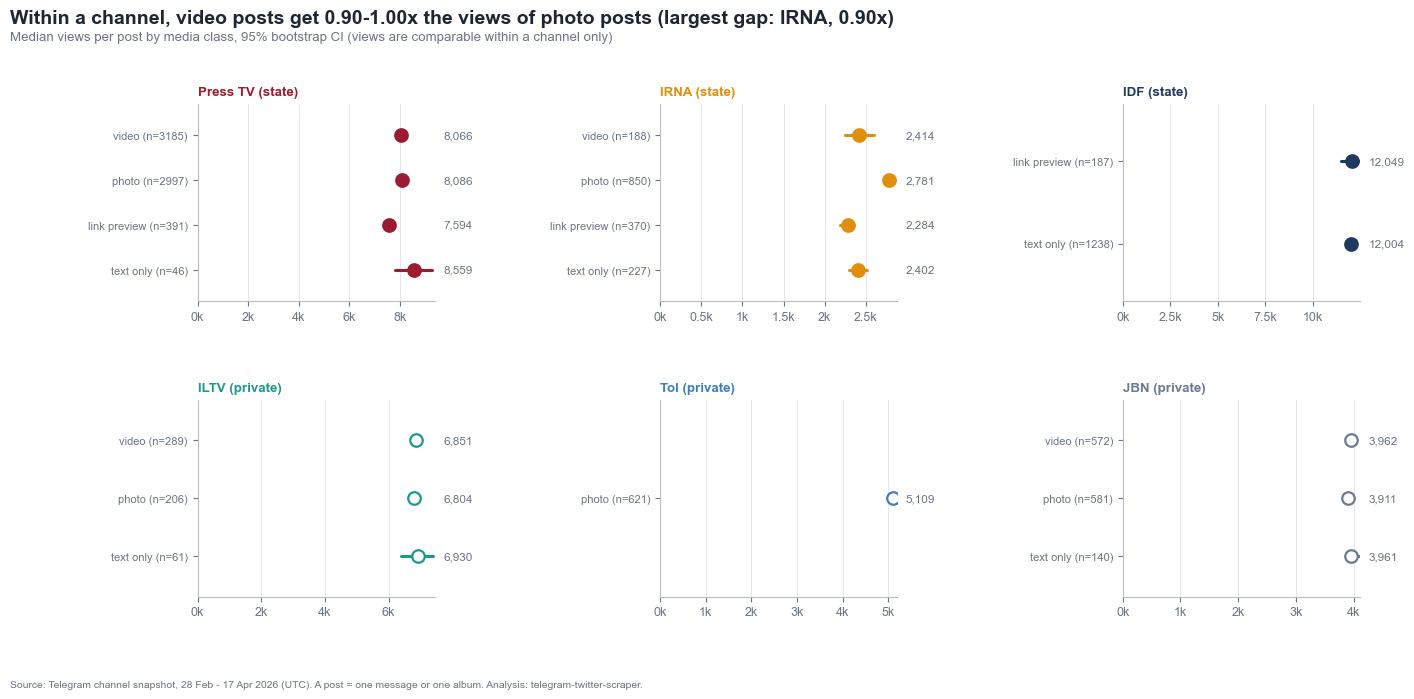

In [7]:
rows = []
for slug in CHANNEL_ORDER:
    for cls in CLASSES:
        v = posts[(posts["channel_slug"] == slug) & (posts["media_class"] == cls)]["views"].astype("float").dropna()
        if len(v) >= 30:
            r = study.bootstrap_median_ci(v, n_boot=3000, seed=study.SEED)
            rows.append({"channel_slug": slug, "channel": SHORT_NAMES[slug], "media_class": cls, "n": r["n"], "median_views": r["median"], "ci_low": r["ci_low"], "ci_high": r["ci_high"]})
vm = pd.DataFrame(rows)
display(vm.pivot(index="channel", columns="media_class", values="median_views").reindex([SHORT_NAMES[s] for s in CHANNEL_ORDER]).round(0))

diffs = []
for slug in CHANNEL_ORDER:
    a = np.log1p(posts[(posts["channel_slug"] == slug) & (posts["media_class"] == "video")]["views"].astype("float").dropna())
    b = np.log1p(posts[(posts["channel_slug"] == slug) & (posts["media_class"] == "photo")]["views"].astype("float").dropna())
    if len(a) >= 30 and len(b) >= 30:
        r = stats.mean_diff_ci(a, b, n_boot=3000, seed=study.SEED)
        diffs.append({"channel_slug": slug, "channel": SHORT_NAMES[slug], "n_video": r["n_a"], "n_photo": r["n_b"], "video_over_photo_views": float(np.exp(r["diff"])), "ci_low": float(np.exp(r["ci_low"])), "ci_high": float(np.exp(r["ci_high"])), "p_welch": r["p_welch"]})
        add_test(f"{SHORT_NAMES[slug]}: views video vs photo (Welch, log views)", "views", r["p_welch"], float(np.exp(r["diff"])), "geometric-mean ratio video/photo")
vdiff = pd.DataFrame(diffs)
display(vdiff.round(4))

fig, axes = plt.subplots(2, 3, figsize=(15, 6.4), gridspec_kw={"hspace": 0.5, "wspace": 0.95})
for ax, slug in zip(axes.ravel(), CHANNEL_ORDER):
    sub = vm[vm["channel_slug"] == slug].reset_index(drop=True)
    if sub.empty: ax.axis("off"); continue
    viz.dot_whisker(ax, sub, label_col="media_class", est_col="median_views", lo_col="ci_low", hi_col="ci_high", slug_col="channel_slug", value_fmt="{:,.0f}")
    ax.set_title(f"{SHORT_NAMES[slug]} ({CHANNELS[slug]['ownership']})", fontsize=9.5, color=viz.CHANNEL_COLORS[slug])
    ax.set_xlim(left=0); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:g}k")); ax.set_yticklabels([f"{c} (n={n})" for c, n in zip(sub["media_class"], sub["n"])], fontsize=8)
big = vdiff.iloc[(vdiff["video_over_photo_views"] - 1).abs().argmax()]
viz.headline(fig, f"Within a channel, video posts get {vdiff['video_over_photo_views'].min():.2f}-{vdiff['video_over_photo_views'].max():.2f}x the views of photo posts (largest gap: {big['channel']}, {big['video_over_photo_views']:.2f}x)",
             "Median views per post by media class, 95% bootstrap CI (views are comparable within a channel only)", y=1.0, wrap=100)
viz.done(fig, "06_views_by_media", vm)

**Reading the figure and table.** Within a channel the median views of video, photo, link-card and text posts are almost the same: Press TV about 7,600-8,600 across classes, JBN 3,900-4,000, ILTV 6,800-6,900. The video/photo ratio in geometric-mean views is 0.995 (0.98-1.01) at Press TV, 0.99 (0.95-1.03) at ILTV, 1.00 (0.99-1.02) at JBN, and only IRNA differs (0.90; 0.85-0.95; video gets about a tenth fewer views than photos). Media type does not move reach in any channel except IRNA, and in the wrong direction for a "visuals drive attention" story. Late-collected views (months after posting) may flatten differences that existed in the first hours.

## 6. One multiple-comparison correction for the whole notebook

In [8]:
tests = pd.DataFrame(TESTS)
tests["p_bh"] = stats.bh_adjust(tests["p_raw"])
tests["significant_bh_0.05"] = tests["p_bh"] < 0.05
display(tests.round(5))
viz.export_data(tests, "06_all_tests_bh")

,test,family,p_raw,effect,effect_name,p_bh,significant_bh_0.05
0,Press TV media vs topic - new coding: video / photo / none,press_tv_topic_split,0.00000,0.33010,bias-corrected Cramer's V,0.00000,True
1,Press TV media vs topic - new coding: any editorial media vs none,press_tv_topic_split,0.00000,0.18237,bias-corrected Cramer's V,0.00000,True
2,Press TV media vs topic - OLD coding: photo-only flag,press_tv_topic_split,0.00000,0.39697,bias-corrected Cramer's V,0.00000,True
3,"Press TV: diplomacy / official actors share, media vs none",press_tv_topic_split,0.00000,-0.13599,difference in proportions,0.00000,True
4,"Press TV: Hormuz / war economy share, media vs none",press_tv_topic_split,0.01278,-0.03673,difference in proportions,0.01661,True
5,"Press TV: Khamenei / Leader and funerals share, media vs none",press_tv_topic_split,0.00584,0.05899,difference in proportions,0.00844,True
6,IRNA media vs topic (chi-square),per_channel_topic_split,0.00000,0.23048,bias-corrected Cramer's V,0.00000,True
7,ILTV media vs topic (chi-square),per_channel_topic_split,0.00020,0.21603,bias-corrected Cramer's V,0.00033,True
8,JBN media vs topic (chi-square),per_channel_topic_split,0.00000,0.30357,bias-corrected Cramer's V,0.00000,True
9,"Press TV: views video vs photo (Welch, log views)",views,0.45986,0.99543,geometric-mean ratio video/photo,0.54347,False


PosixPath('/Users/lfpmb/Documents/telegram-twitter-scraper/docs/study/data/06_all_tests_bh.csv')

**Reading the table.** Thirteen tests were run in this notebook (media-by-topic chi-squares, three two-proportion tests, per-channel chi-squares for IRNA, ILTV and JBN, and four video-vs-photo view tests). After Benjamini-Hochberg adjustment 10 of 13 are significant at 0.05; the three that are not are the video-vs-photo view comparisons at Press TV, ILTV and JBN. With thousands of posts, p-values for the topic tests are astronomically small (BH-adjusted p ≈ 1e-177 for Press TV), so read effect sizes, not p-values: V = 0.33 at Press TV against 0.30 at JBN, 0.23 at IRNA and 0.22 at ILTV, which is the same range. Media format tracks topic at every channel with enough variety to test; Press TV is not special.

In [9]:
chi_new = chi.loc["new coding: video / photo / none"]; chi_old = chi.loc["OLD coding: photo-only flag"]
p_new = float(tests.loc[tests["test"].str.contains("new coding: video"), "p_bh"].iloc[0]); p_old = float(tests.loc[tests["test"].str.contains("OLD coding"), "p_bh"].iloc[0])
_ = study.record_findings("06_media", {
    "media_shares_ci": mix,
    "press_tv_media_vs_topic_chi_square": {
        "new_coding_video_photo_none": {**{k: chi_new[k] for k in ("n", "chi2", "dof", "p_value", "cramers_v_bias_corrected")}, "p_bh": p_new, "collapsed_topics_table_cols": int(chi_new["n_categories"])},
        "old_photo_only_flag": {**{k: chi_old[k] for k in ("n", "chi2", "dof", "p_value", "cramers_v_bias_corrected")}, "p_bh": p_old},
    },
    "press_tv_topic_groups_media_vs_none": claims,
    "per_channel_media_vs_topic": per_channel,
    "views_by_media_kind": vm,
    "views_video_over_photo": vdiff,
    "all_tests_bh": tests,
})

## What this means for the article

- **Retire "Press TV uses visuals strategically for diplomacy" (Nye).** It rested on counting videos as no media. Press TV is a video-and-photo feed (93% of posts) with almost no plain text, and its diplomacy content is more likely to appear as a photo or link card than as video.
- **If a media claim is wanted, make it about format and content type**: rally and commentary footage is video, official-actor stories are photos, analysis pieces are link cards. The same media-follows-topic pattern appears at JBN, IRNA and ILTV.
- **Engagement**: media type does not change views in any channel but IRNA. Do not claim that visuals earn attention.
- **Say that ToI is structurally all photo** (99.8%) and the IDF structurally text (87%), so neither can be compared on media strategy.